In [1]:
import numpy as np
import sklearn as skl
import matplotlib.pyplot as plt
import pandas as pd
import yfinance as yf
import seaborn as sb

# Parameters and function definitions

## Parameters

In [31]:
# Loading stock data
n_stocks = 20
start_time = '1980-01-01'
end_time = '2020-01-01'
min_cover = 0.90
random_seed = 0

# Plotting parameters
n_sample = 10

# Preprocessing parameters
tt_ratio = 0.8
ev_ratio_cut = 0.95

## Helper functions

In [2]:
import requests
from io import StringIO

def get_sp500_tickers() -> list[str]:
    url = "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies"
    headers = {"User-Agent": "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/125.0 Safari/537.36"}

    resp = requests.get(url, headers=headers, timeout=10)
    resp.raise_for_status()

    tables = pd.read_html(StringIO(resp.text))
    sp500 = tables[0]

    return sp500["Symbol"].str.replace(".", "-", regex=False).tolist()

In [3]:
import random

def download_random_tickers(
    n: int,
    start: str,
    end: str,
    universe: list[str] | None = None,
    max_attempts: int = 3,
    min_coverage: float = 0.98,
    seed: int | None = None,
) -> pd.DataFrame:
    """
    Download n random tickers' daily returns, restricted to those with
    (near-)complete data over [start, end].

    Parameters
    ----------
    universe : candidate ticker list to sample from. If None, pulls
        current S&P 500 constituents from Wikipedia as a default universe.
    min_coverage : minimum fraction of expected trading days a ticker
        must have non-NaN adjusted close data for, to be kept.
    max_attempts : how many extra sampling rounds to run to backfill
        tickers that get dropped for insufficient coverage.

    Returns
    -------
    DataFrame of daily simple returns, columns = tickers, index = dates.
    """
    rng = random.Random(seed)

    if universe is None:
        universe = get_sp500_tickers()

    expected_trading_days = len(pd.bdate_range(start, end))  # rough approx, ignores holidays

    kept = {}
    tried = set()
    pool = universe.copy()
    rng.shuffle(pool)

    attempt = 0
    while len(kept) < n and pool and attempt < max_attempts + 1:
        batch_size = min(len(pool), (n - len(kept)) * 2)  # oversample to absorb dropouts
        batch = [pool.pop() for _ in range(batch_size)]
        tried.update(batch)

        data = yf.download(
            batch, start=start, end=end, auto_adjust=True,
            progress=False, group_by="ticker", threads=True,
        )

        for tkr in batch:
            try:
                close = data[tkr]["Close"] if len(batch) > 1 else data["Close"]
            except (KeyError, TypeError):
                continue  # ticker failed to download at all

            coverage = close.notna().sum() / expected_trading_days
            if coverage >= min_coverage:
                kept[tkr] = close

            if len(kept) >= n:
                break

        attempt += 1

    if len(kept) < n:
        raise ValueError(
            f"Only found {len(kept)}/{n} tickers meeting coverage threshold "
            f"in [{start}, {end}]. Try a larger universe or lower min_coverage."
        )

    prices = pd.DataFrame(kept).sort_index(axis=1)
    prices = prices.loc[start:end]
    returns = prices.pct_change().dropna(how="all")

    return returns.iloc[:, :n]  # trim any oversample overshoot

# Dowloading a random selection of tickers

In [ ]:
tickers = download_random_tickers(n=n_stocks, 
                                  start=start_time, 
                                  end=end_time, 
                                  min_coverage=min_cover,
                                  seed=random_seed)

$ABNB: Data doesn't exist for startDate = 315550800, endDate = 1577854800
$HOOD: Data doesn't exist for startDate = 315550800, endDate = 1577854800

2 Failed downloads:
['ABNB', 'HOOD']: Data doesn't exist for startDate = 315550800, endDate = 1577854800
$VLTO: Data doesn't exist for startDate = 315550800, endDate = 1577854800

1 Failed download:
['VLTO']: Data doesn't exist for startDate = 315550800, endDate = 1577854800


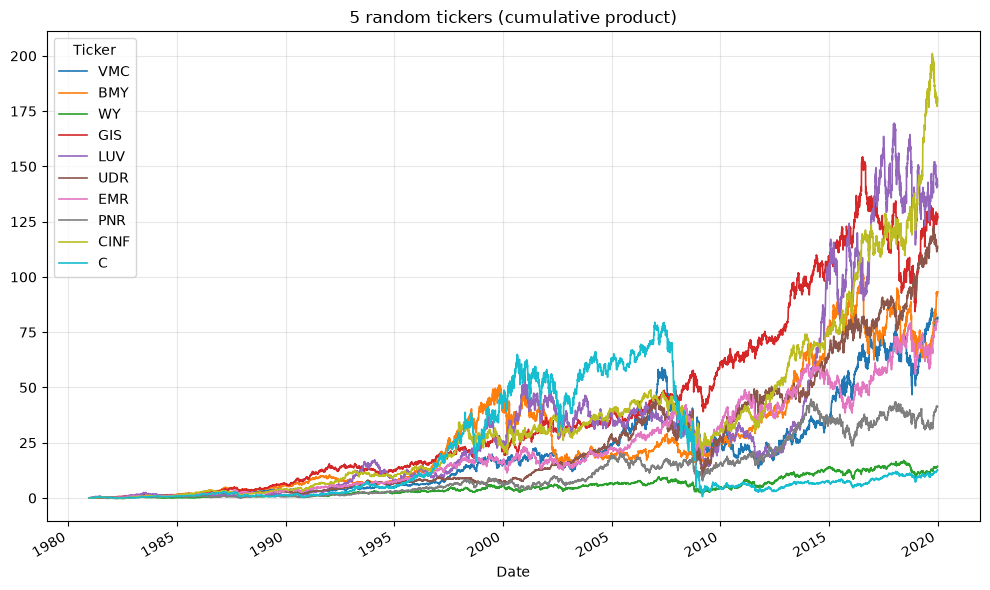

In [ ]:
cp = (1 + tickers.dropna().sample(
        n=n_sample, 
        axis=1,
        random_state=0
        )).cumprod() - 1

ax = cp.plot(
            figsize=(10, 6),
            title=f"{5} random tickers (cumulative product)",
            linewidth=1.2,
    )
ax.set_xlabel("Date")
ax.legend(title="Ticker", loc="best")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Preprocessing: train/test split, regularisation and PCA -> factors

In [ ]:
from sklearn.preprocessing import StandardScaler

tickers_dropped = tickers.dropna()
split = int(tt_ratio * len(tickers_dropped))
train, test = tickers_dropped.iloc[:split], tickers_dropped.iloc[split:]

scaler = StandardScaler().set_output(transform='pandas')
train_scaled = scaler.fit_transform(train)
test_scaled = scaler.transform(test)

print("Rescaled training set (AAPL):\n", train_scaled['AAPL'].describe())
print("\nRescaled test set (AAPL):\n", test_scaled['AAPL'].describe())

Rescaled training set (AAPL):
 count    7.876000e+03
mean     1.623891e-17
std      1.000063e+00
min     -1.678031e+01
25%     -5.323391e-01
50%     -3.674986e-02
75%      5.063488e-01
max      1.068938e+01
Name: AAPL, dtype: float64

Rescaled test set (AAPL):
 count    1970.000000
mean       -0.008507
std         0.520459
min        -4.025236
25%        -0.253783
50%        -0.015879
75%         0.267522
max         2.827839
Name: AAPL, dtype: float64


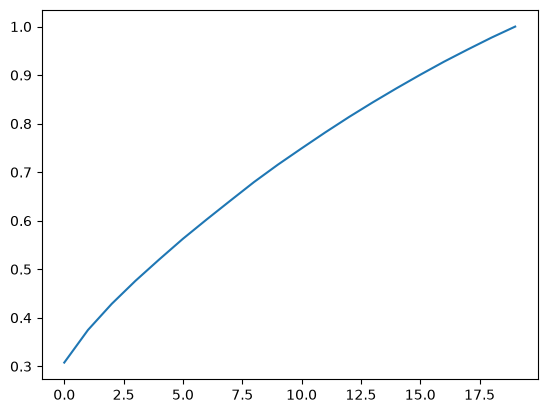

In [28]:
from sklearn.decomposition import PCA
general_pca = PCA()
general_pca.fit_transform(train_scaled);
plt.plot(general_pca.explained_variance_ratio_.cumsum())

<Axes: xlabel='Date'>

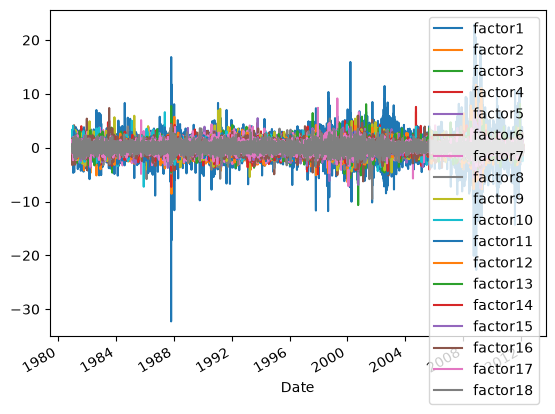

In [ ]:
pca = PCA(n_components=ev_ratio_cut)
ds_reduced = pca.fit_transform(train_scaled)

factors = pd.DataFrame(
    ds_reduced,
    index=train_scaled.index,
    columns=[f"factor{i+1}" for i in range(ds_reduced.shape[1])],
)

factors.plot()